# Fibro compartment: scVI integration of clean data

In [1]:
import sys 
import os
from datetime import datetime

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import scvi
import hdf5plugin

import matplotlib.pyplot as plt
import seaborn as sns

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = os.path.split(os.getcwd())[0]
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts')

import torch
torch.cuda.is_available()

%reload_ext autoreload
%autoreload 2

from scvi_wrapper2 import run_scvi

In [2]:
import celltypist

In [3]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100
import matplotlib
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [4]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
general_data_path = '/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data'

In [5]:
def regen_embed (adata, anno2show):
    sc.pp.neighbors(adata, use_rep = 'X_scVI')
    sc.tl.umap(adata, min_dist = 0.1, spread = 1)
    sc.pl.umap(adata, color = anno2show)
    return (adata)

In [6]:
def ctypist_anno(adata, model, col_name, mv = False, clusters = None):
    import celltypist
    predictions = celltypist.annotate(adata, model=model, majority_voting = mv, over_clustering = clusters)
    predictions.to_adata(prefix=f'ctypist_{col_name}_')
    if mv:
        sc.pl.umap(adata, color = f'ctypist_{col_name}_majority_voting', frameon = False)
    else:
        sc.pl.umap(adata, color = f'ctypist_{col_name}_predicted_labels', frameon = False)

In [7]:
def run_leiden(adata, resolutions, key_name,restrict_to = None, legend_loc = "on data", legend_fontsize = 4):
    for r in resolutions:
        if restrict_to:
            sc.tl.leiden(adata, restrict_to = restrict_to, resolution = r, key_added = f'{key_name}-leiden_r{str(r)}',
                        flavor="igraph", n_iterations=2)
        else:
            sc.tl.leiden(adata, resolution = r, key_added = f'{key_name}-leiden_r{str(r)}',
                        flavor="igraph", n_iterations=2)
    sc.pl.umap(adata, color = [f'{key_name}-leiden_r{str(r)}' for r in resolutions] , legend_loc = legend_loc, legend_fontsize = legend_fontsize)


In [8]:
from utils_vk8 import regen_embed, ctypist_anno, run_leiden, remove_small_samples
from utils import update_obs

In [9]:
from scvi_wrapper2 import run_scvi

In [5]:
general_mrkrs = ['PTPRC', 'CD3G', 
               'HOXA9', 
               'HES1', #DN
               'RORC', #DP
               'CCR9',
              'PDCD1', #CD8aa
              'CD8A', 'CD8B', 
              'CD4', 'CD40LG', 
              'CRTAM', 'ANXA1', #memory
             'FOXP3', 'DHRS3', 
               'TRDC', #gama-delta 
              'EOMES', 'KLRD1', # NK cells
              'TNFSF11', # ILC
              'CD19', 'VPREB1', # pre-pro B cells
              'IGHD', 'IGHA1', 'IGHG1', 
              'CLEC9A', 'CLEC10A', 
              'LAMP3', 
             'LILRA4','S100A9', 'C1QA', 'TPSB2', 'ITGA2B', 'GYPA', 
              'PDGFRA', 'COLEC11', 'FBN1', 
              'RGS5', 'CDH5', 
               'LYVE1', 'EPCAM', 'PSMB11', 'DLK2', 'KRT14', 
               'CCL19', 'AIRE', 'KRT1', 'POU2F3',
               'MYOD1', 'NEUROG1']

In [6]:
fbs_mrkrs_dict2 = {'General': ['PDGFRA','PDGFRB', "VIM"],
               'InterLobular': ['PTX3', 'HMGA1', 'FOSL1', 'TNFRSF12A', 'FBN1', 'PI16', 'MFAP5', 'SEMA3C'],
                  'Adipocyte': ['PPP1R1A', 'PLIN1', 'AQP7', 'PCK1'],
             'PeriLobular': ['COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'],
             'Medullary': ['HLA-DRA', 'CCL19', 'CCL21','CXCL9', 'CXCL10', 'RGS5'],
             'ECM/signalling mols': ['SBSPON', 'HEY1', 'LTBP1'],
             'FDC': ['FDCSP', 'CXCL13', 'CR1', 'CR2', 'ITGAM'], 
           # 'Endo-contamination': ['CDH5', 'PECAM1', 'VWF'],
             }
fbs_mrkrs2=[]
[fbs_mrkrs2.extend(fbs_mrkrs_dict2[key]) for key in fbs_mrkrs_dict2.keys()]

[None, None, None, None, None, None, None]

In [7]:
fbs_mrkrs_full = {'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
             'Interlobular (PI16 progenitor)': ['MFAP5', 'CD55', 'FBN1','SEMA3C', 'PI16','PCOLCE2'],
             'Intermediate': ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
             'Parenchymal': ['C7', 'APOD', 'FBLN5', 'MFAP4', 'LUM', 'FMO2'],
             'Perilobular (progenitor)': ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'],
             'Medullary (antigen-presenting)': ['HLA-DRA',  'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
             'FDC':['CXCL13', 'FDCSP'],
             'Adipose': ['CXCL12','PPARG', 'APOE', 'PPP1R1A', 'PLIN1', 'LIPE','CIDEA', 'MRAP', 'AQP7']
             }
fbs_mrkrs_full_lst=[]
[fbs_mrkrs_full_lst.extend(fbs_mrkrs_full[key]) for key in fbs_mrkrs_full.keys()]

[None, None, None, None, None, None, None, None]

## Load Fbs

In [8]:
adata = ad.read_h5ad(f'{data_path}/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_FB_v2_2layers_300epochs_batch-sample2025-01-16.zarr')

all_obs = pd.read_csv('/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data/objects/rna/thyAgeing_all_scvi_v4_2025-02-04_curatedAnno_v8.csv',
                 index_col = 0)
adata.obs[['taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1','taa_l0', 'anno_status']] = all_obs.reindex(adata.obs_names)[['taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1','taa_l0', 'anno_status']].copy()

In [ ]:
meta = pd.read_excel('/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data/metadata/Thymus_ageing_metadata_v28_2025-03-13.xlsx')
from utils import update_obs
update_obs(adata, meta, update_cols = ['age_group'])

In [ ]:
adata = adata[~adata.obs['taa_l5'].isnull(),].copy()

In [ ]:
sc.pl.umap(adata, color = ['taa_l5', 'donor'], legend_loc = "on data", legend_fontsize = 5, frameon = False)

In [17]:
adata = remove_small_samples(adata, sample_anno = 'sample', less_than=3)

['Z12-THY--SC-EPCP-1', 'T07_TH_EPCAM_S3']
3 cells were removed


In [20]:
adata.layers['counts'].data

array([1, 1, 4, ..., 2, 2, 1], dtype=uint32)

In [21]:
adata.X = adata.layers['counts'].copy()

In [22]:
adata

AnnData object with n_obs × n_vars = 70255 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse', 'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet_verbose', 'anno_status'
    var: 'gene_ids', 'gene_name', 'n_counts', 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'age_cont_colors', 'che

Removed excluded genes


Unable to initialize backend 'cuda': 
Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Highly variable genes selected in total (70255, 10000)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 400/400: 100%|██████████████| 400/400 [40:10<00:00,  6.02s/it, v_num=1, train_loss_step=2.68e+3, train_loss_epoch=2.7e+3]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████████| 400/400 [40:10<00:00,  6.03s/it, v_num=1, train_loss_step=2.68e+3, train_loss_epoch=2.7e+3]
scVI model trained
UMAP performed


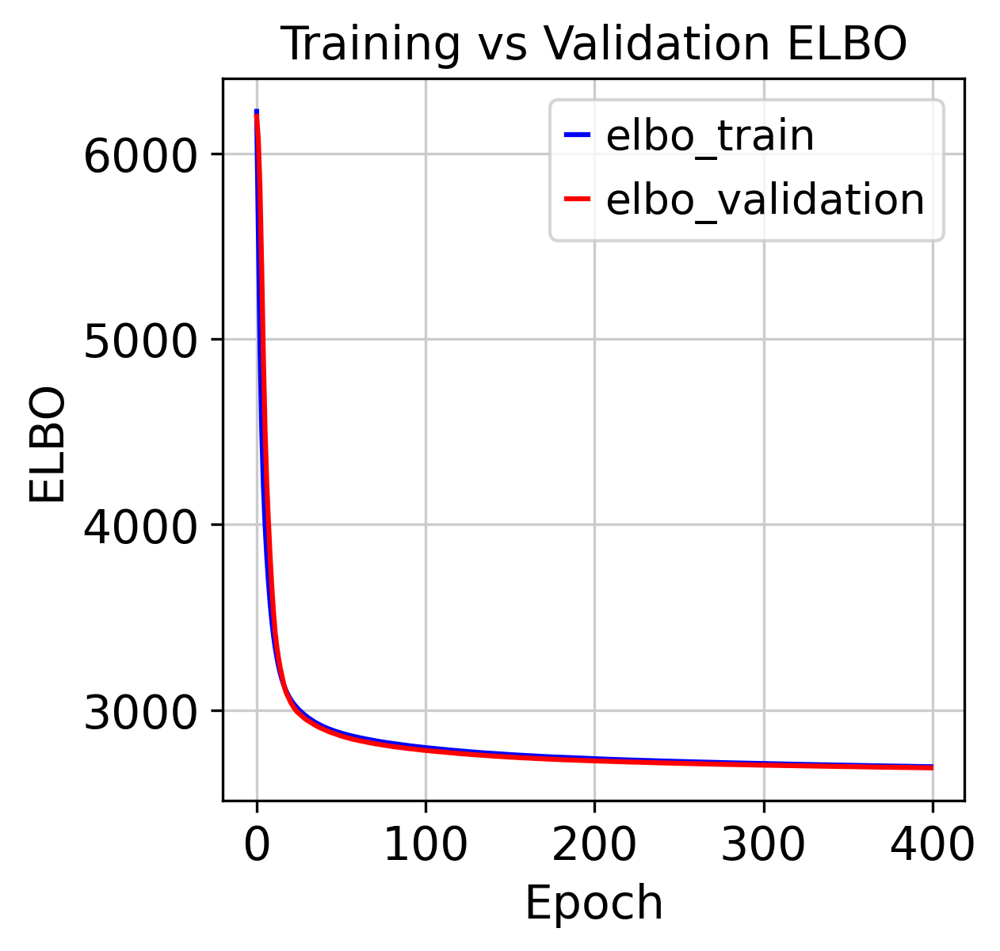

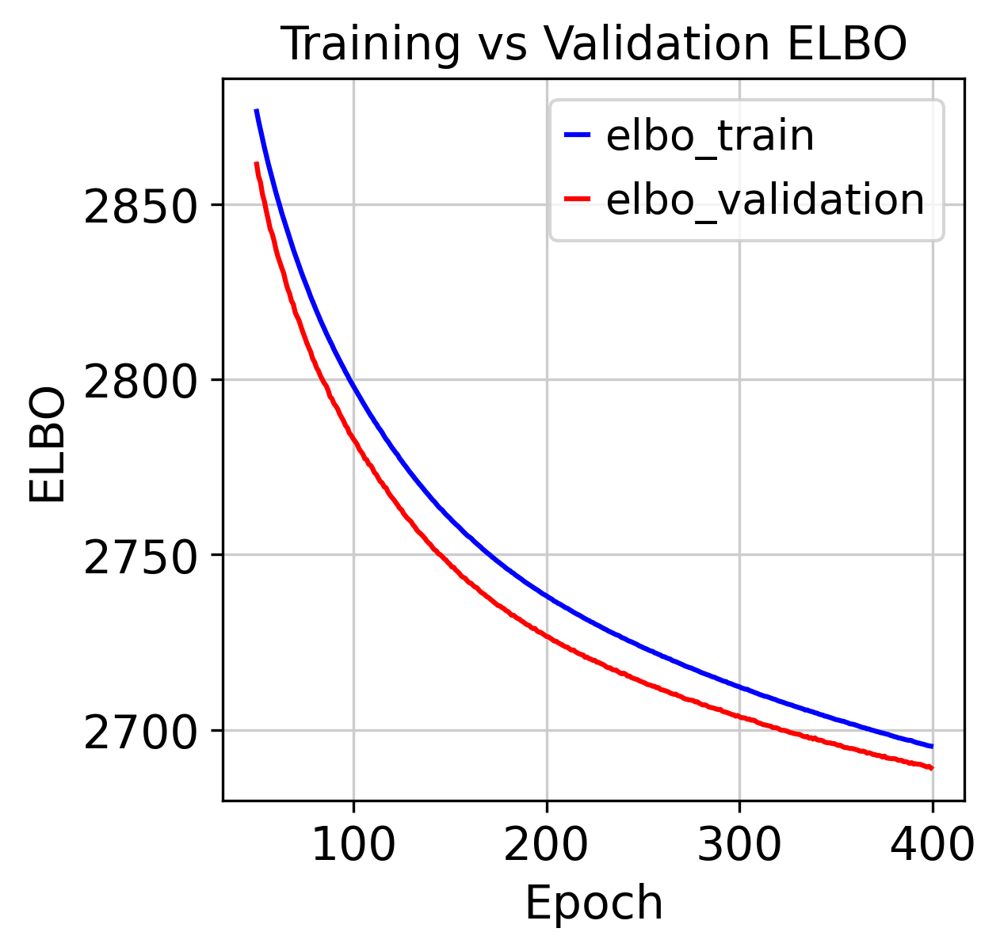

Plotting doublet_metric
Plotting age
Plotting batch_mixing
Plotting cat_covs
Plotting cont_covs


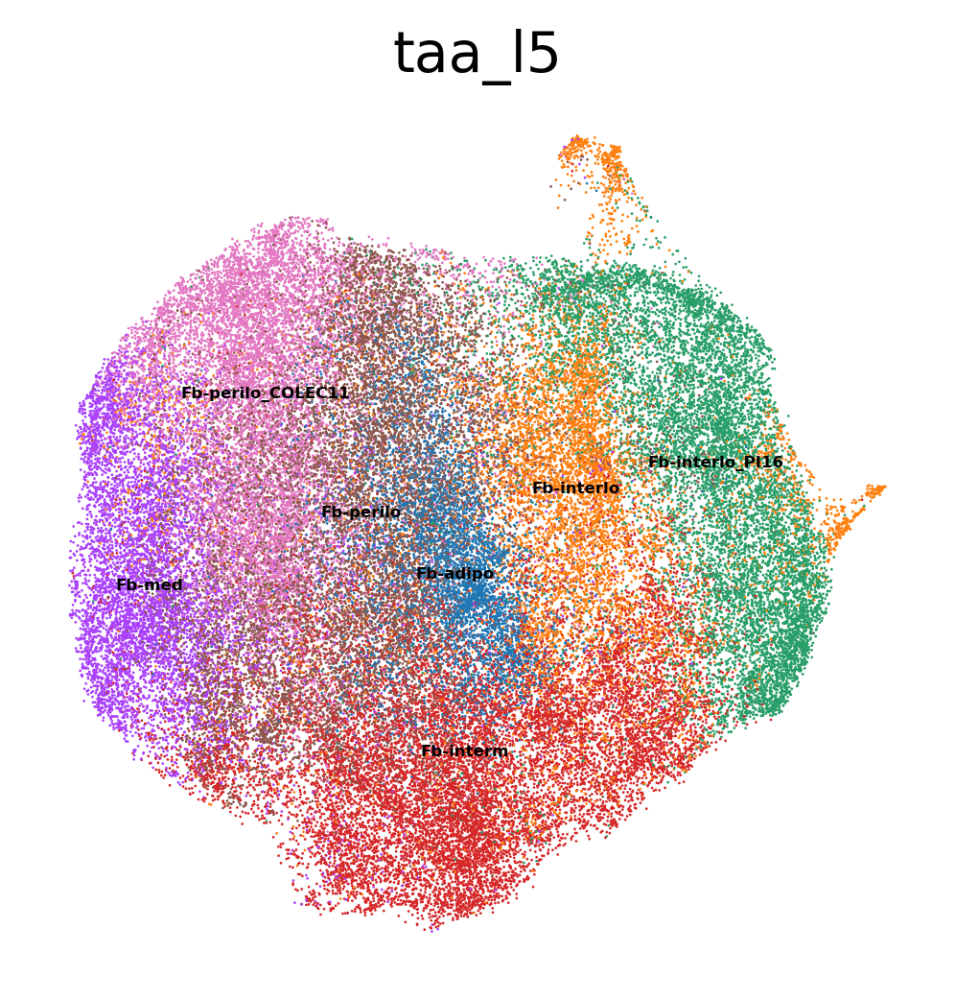

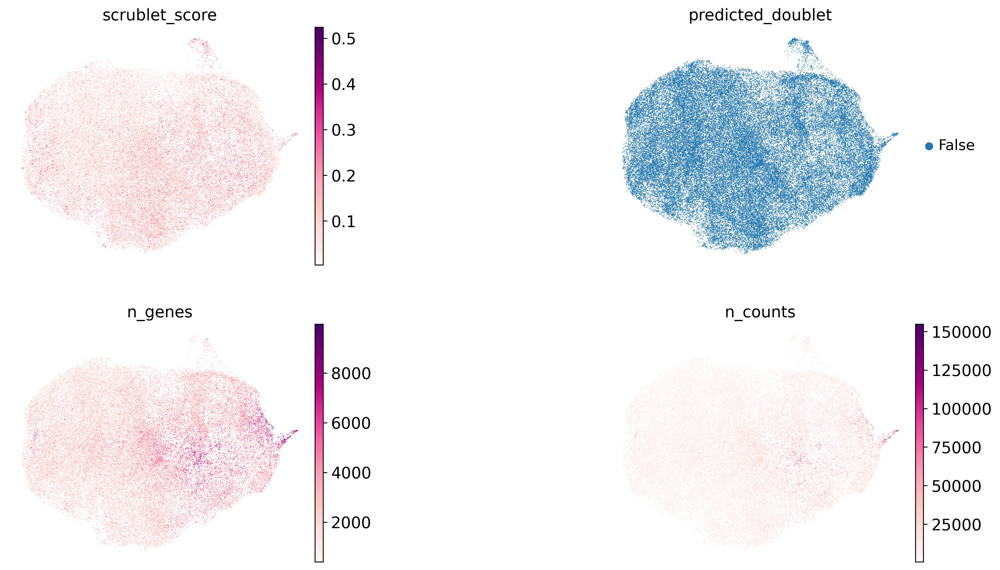

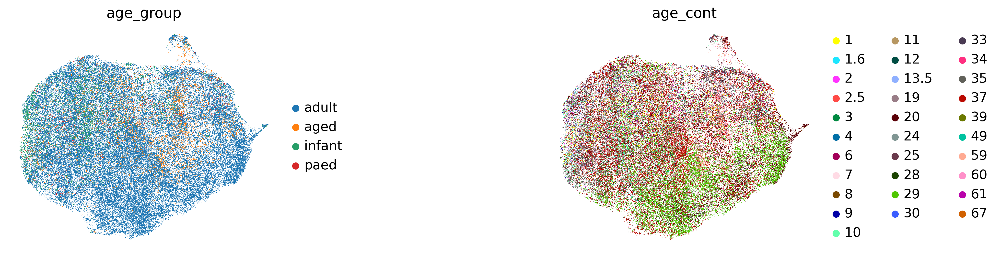

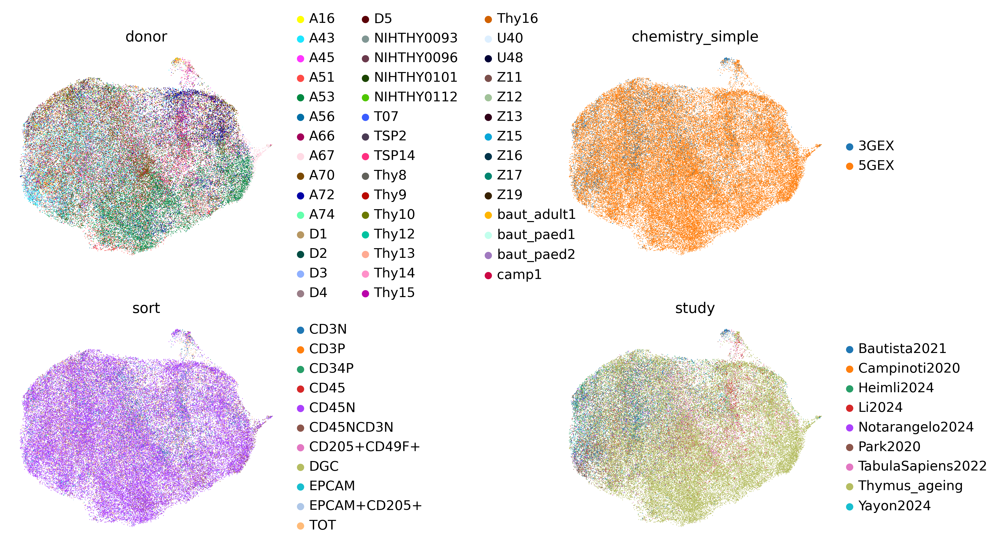

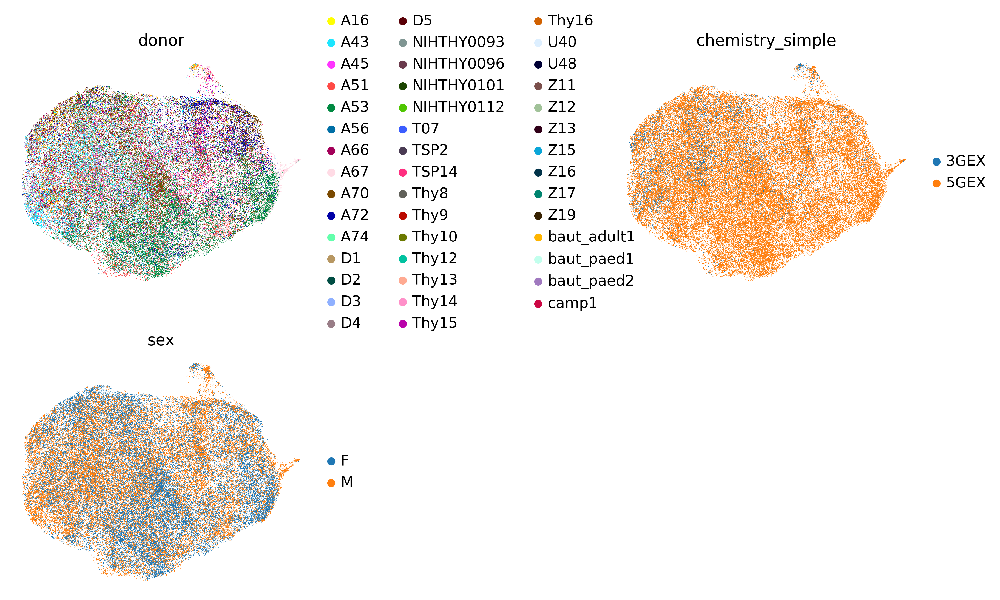

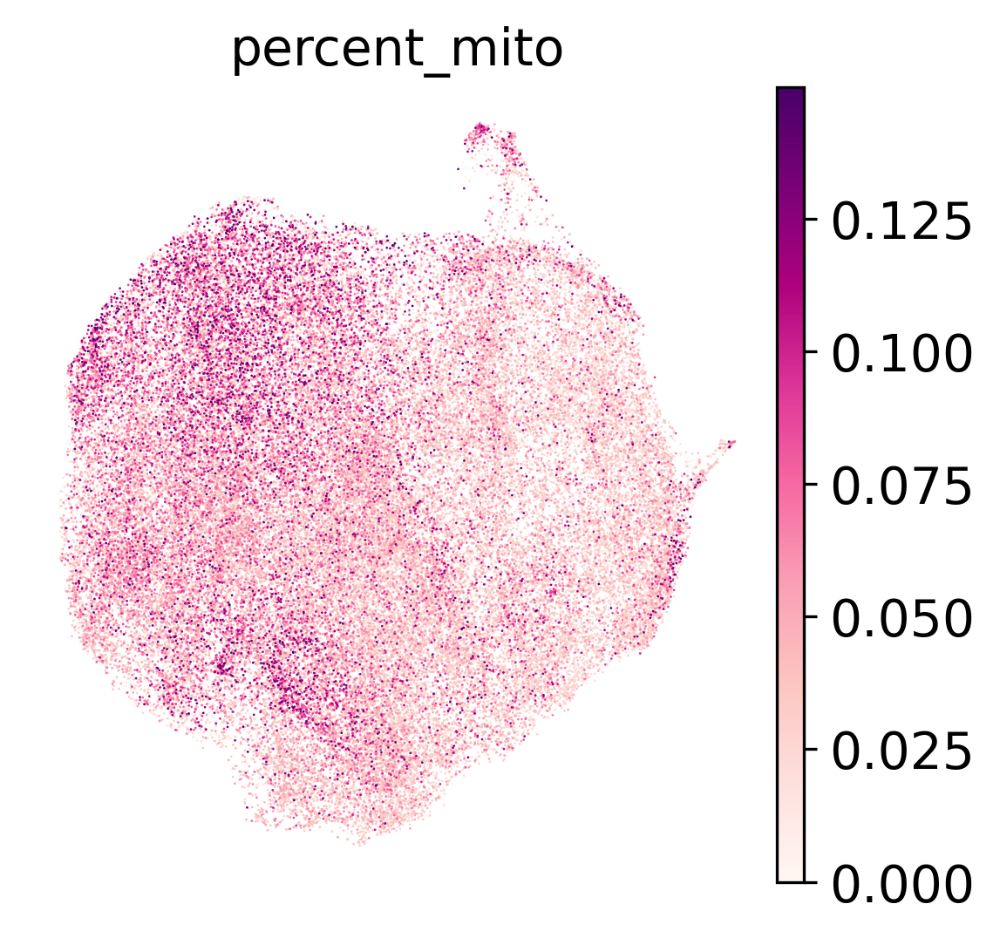

In [23]:
scvi_run = run_scvi(adata, 
                    # Excluded genes
                    include_genes=[], exclude_cc_genes=True, exclude_mt_genes=True, 
                    exclude_vdjgenes = True, remove_cite = False,
                    # Highly variable gene selection
                    batch_hv="age_group", hvg = 10000, span = 0.5,
                    # scVI 
                    batch_scvi="sample",
                    cat_cov_scvi=["donor", "chemistry_simple", "sex"], 
                    max_epochs=400, batch_size=2000, early_stopping = False, # early_stopping_patience = 15, early_stopping_min_delta = 10,
                    plan_kwargs = {'lr': 0.0001}, n_layers = 3, n_latent = 30, dispersion = 'gene-batch',
                                      check_val_every_n_epoch = 1,
                    # Leiden clustering
                    leiden_clustering = None, col_cell_type = 'taa_l5',
                   covs = {'doublet_metric': ['scrublet_score', 'predicted_doublet', 'n_genes', 'n_counts'],
                    'age': ['age_group', 'age_cont'],
                    'batch_mixing': ['donor', 'chemistry_simple', 'sort', 'study']})

In [27]:
# Save adata and scvi model
scvi_embed_version = 'scvi_v3_2024-11-05_tec-fb-vascSplit'
scvi_obj_version = f'FB_v3_3layers_400epochs_batch-sample_{datetime.now().strftime("%Y-%m-%d")}'
overwrite = True

#anno_cols = [c for c in scvi_run['data'].obs.columns if '_pred_' in c or '_prop_' in c]
if not os.path.exists(f'{data_path}/objects/thyAgeing_{scvi_embed_version}_{scvi_obj_version}.zarr') or overwrite:
#    scvi_run['data'].obs = scvi_run['data'].obs.drop(columns=anno_cols)
    scvi_run['data'].write_h5ad(
        f'{data_path}/objects/thyAgeing_{scvi_embed_version}_{scvi_obj_version}.zarr',
        compression=hdf5plugin.FILTERS["zstd"],
        compression_opts=hdf5plugin.Zstd(clevel=5).filter_options,
    )

In [28]:
scvi_run['vae']

SCVI model with the following parameters: 
n_hidden: 128, n_latent: 30, n_layers: 3, dropout_rate: 0.1, dispersion: gene-batch, gene_likelihood: zinb, 
latent_distribution: normal.
Training status: Trained
Model's adata is minified?: False

In [29]:
scvi_run['vae'].save(f'{model_path}/thyAgeing_{scvi_embed_version}_{scvi_obj_version}', save_anndata=True, overwrite=False)

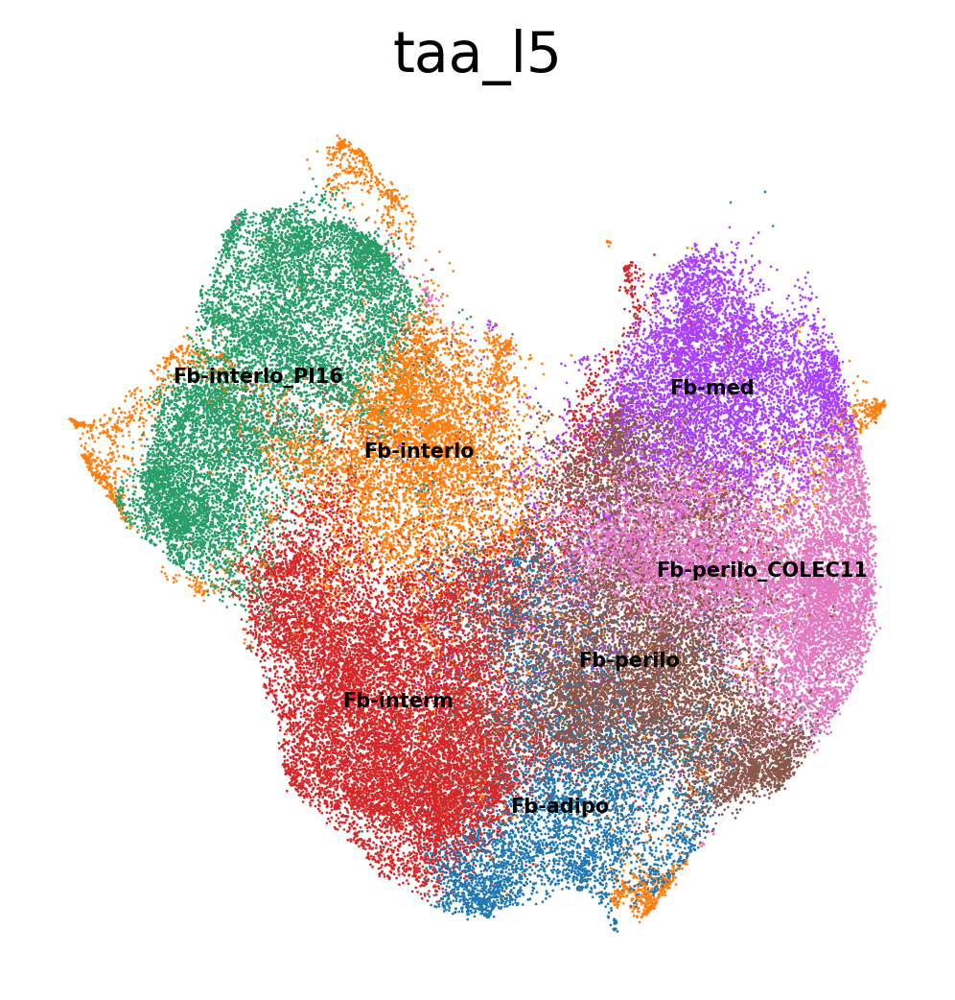

In [33]:
sc.pl.umap(adata, color = ['taa_l5'], legend_loc = "on data", legend_fontsize = 5, frameon = False)

In [35]:
adata.obs['taa_l5'].cat.categories

Index(['Fb-adipo', 'Fb-interlo', 'Fb-interlo_PI16', 'Fb-interm', 'Fb-med',
       'Fb-perilo', 'Fb-perilo_COLEC11'],
      dtype='object')

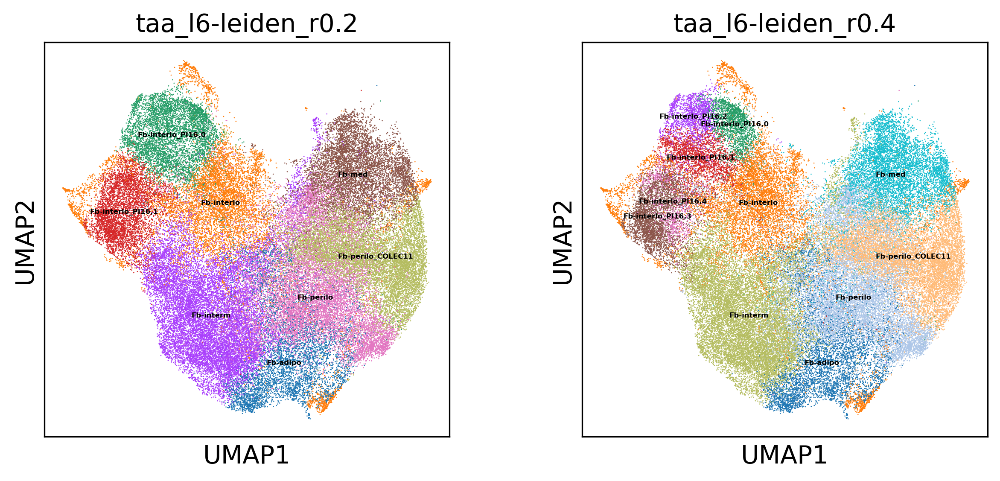

In [39]:
run_leiden(adata, resolutions = [0.2, 0.4], restrict_to=['taa_l5', ['Fb-interlo_PI16']], 
          key_name = 'taa_l6')

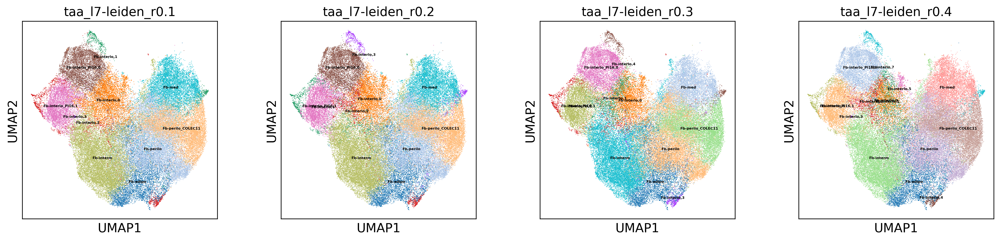

In [41]:
run_leiden(adata, resolutions = [0.1, 0.2, 0.3, 0.4], restrict_to=['taa_l6-leiden_r0.2', ['Fb-interlo']], 
          key_name = 'taa_l7')

In [ ]:
vae = scvi.model.SCVI.load(f'{model_path}/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_FB_v2_2layers_300epochs_batch-sample2025-01-16')

In [ ]:
def scvi_markers_enrich(vae, cluster, adata, prep_vae = True, enrich = True, n_markers=5):
    if prep_vae:
        vae.adata.obs[cluster] = adata.obs.reindex(vae.adata.obs_names)[cluster].copy()
    results = {}
    de_mrks_dict = {}
    de_df = vae.differential_expression(
    groupby=cluster)
    de_df['cluster'] = [i.replace(" vs Rest","") for i in de_df['comparison']]
    de_df.head()
    markers = {}
    cats = vae.adata.obs[cluster].cat.categories
    for i, c in enumerate(cats):
        cid = "{} vs Rest".format(c)
        cell_type_df = de_df.loc[de_df.comparison == cid]
        cell_type_df = cell_type_df[cell_type_df.lfc_mean > 1]
        cell_type_df = cell_type_df[cell_type_df["bayes_factor"] > 2]
        cell_type_df = cell_type_df[cell_type_df["non_zeros_proportion1"] > 0.1]
        de_mrks_dict[c]=cell_type_df.index.tolist() 
        markers[c] = cell_type_df.index.tolist()[:n_markers]
    de_mrks_dict = {k: v for k, v in de_mrks_dict.items() if v}
    if enrich:
        enrich_df = sc.queries.enrich(de_mrks_dict,gprofiler_kwargs={'sources': ['GO:BP', 'REAC', 'KEGG'], 
                                                                     'no_evidences': False, 'all_results': True}, 
                                      org="hsapiens")
        enrich_df.significant = enrich_df.p_value<0.1
     #  enrich_df = enrich_df.loc[((enrich_df.term_size > 10) & (enrich_df.term_size < 500)) & (enrich_df.significant == True)].reset_index(drop = True)
        print(f"Number of significant genes:{str(enrich_df.significant.sum())}")
        results['enrich'] = enrich_df
    results['de_df'] = de_df
    results['markers'] = markers
    #print(results)
    return(results)

In [215]:
fb_mrkrs = scvi_markers_enrich(vae = vae, cluster = 'taa_l7-leiden_r0.2', adata = adata, enrich = False)

DE...: 100%|███████████████████████████████████████████████████████████████████████████████████| 11/11 [03:20<00:00, 18.27s/it]


In [52]:
fb_mrkrs['markers']

{'Fb-adipo': ['PLIN1', 'CIDEC', 'GPD1', 'PPP1R1A', 'SMOC1'],
 'Fb-interlo,0': ['OGN', 'MEGF6', 'PI16', 'SFRP4', 'SEMA3B'],
 'Fb-interlo,1': ['DIAPH3', 'P4HA3', 'PCLAF', 'COL1A1', 'TUBB3'],
 'Fb-interlo,2': ['CA12', 'HP', 'CGREF1', 'ALPL', 'STEAP1'],
 'Fb-interlo,3': ['RPS4Y1', 'COL1A1', 'COL3A1', 'PPP1R14B', 'RAB13'],
 'Fb-interlo_PI16,0': ['NOVA2', 'ENPP6', 'IL18', 'ANXA3', 'LVRN'],
 'Fb-interlo_PI16,1': ['LINC01133', 'ALDH1A3', 'HRH1', 'HAS1', 'BMP8B'],
 'Fb-interm': ['PTX3', 'IL1RL1', 'CSF3', 'HMOX1', 'TM4SF1'],
 'Fb-med': ['FRZB', 'CCL19', 'ANKRD29', 'GP1BA', 'CCL21'],
 'Fb-perilo': ['MTRNR2L8', 'ABCA10', 'GHR', 'ABCB11', 'DNAJB1'],
 'Fb-perilo_COLEC11': ['COLEC11', 'FRZB', 'LAMC3', 'COL6A6', 'RET']}

In [55]:
sc.pp.normalize_total(adata, target_sum = 1e4)
sc.pp.log1p(adata)

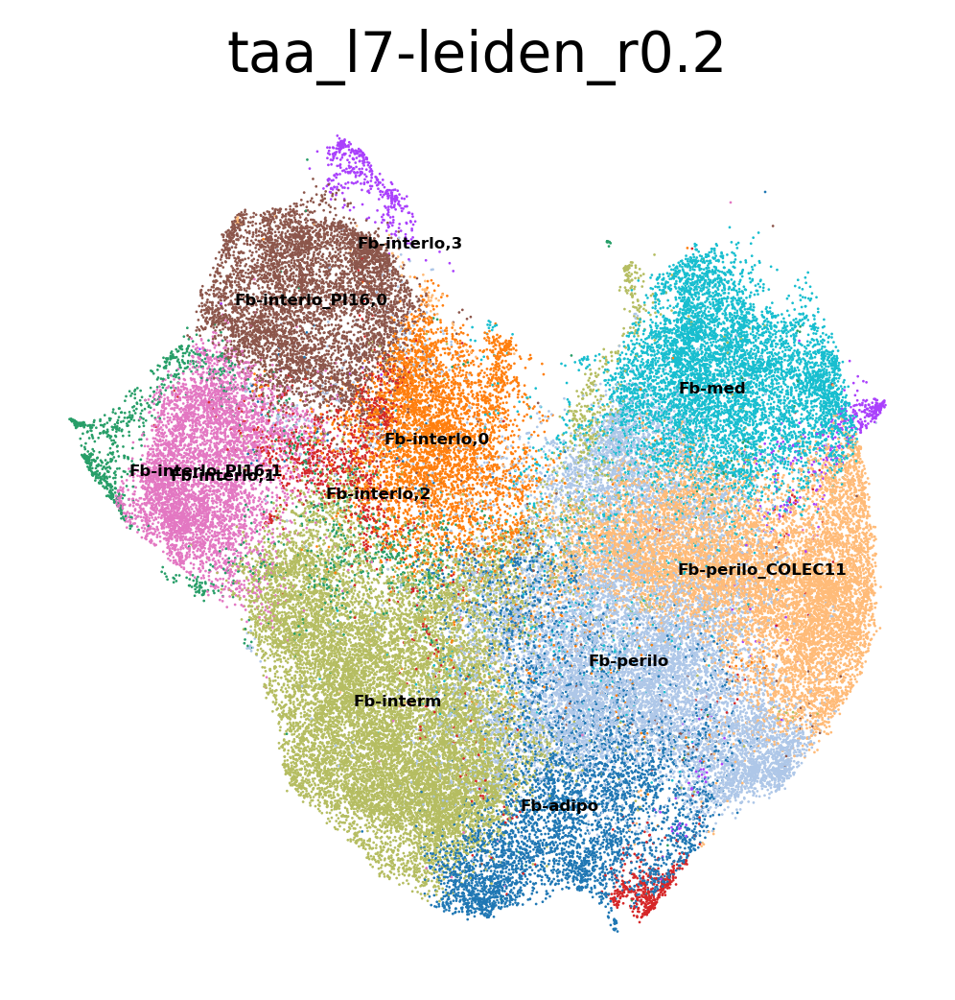

In [62]:
sc.pl.umap(adata, color = ['taa_l7-leiden_r0.2'], legend_loc = "on data", legend_fontsize = 4, frameon = False)

In [68]:
adata.obs['taa_l5_old'] = adata.obs['taa_l5'].copy()

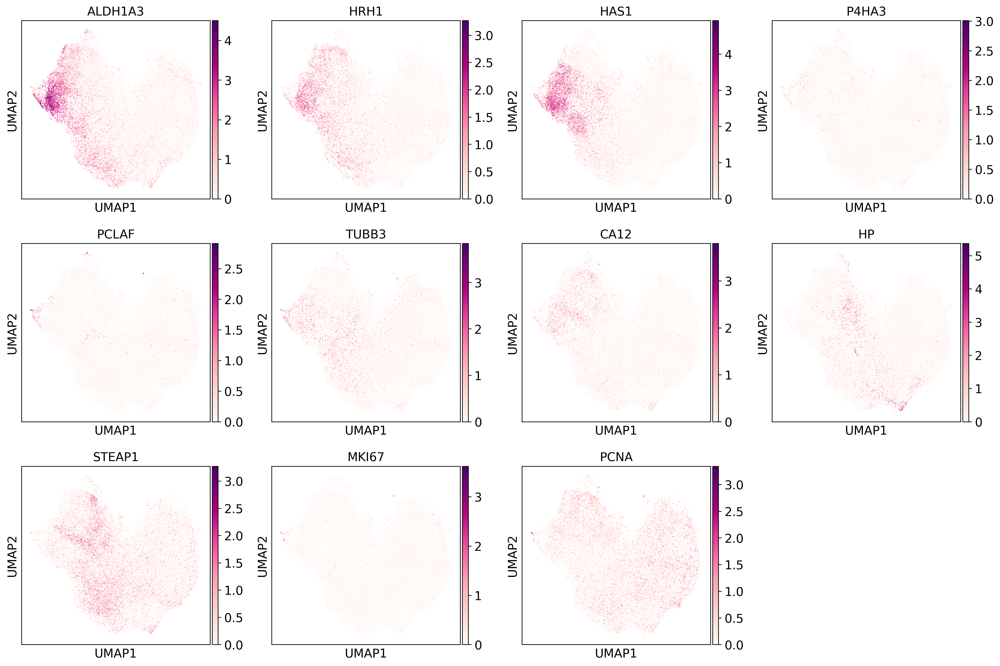

In [63]:
sc.pl.umap(adata, color = ['ALDH1A3', 'HRH1', 'HAS1', 'P4HA3', 'PCLAF', 'TUBB3', 'CA12', 'HP', 'STEAP1', 'MKI67', 'PCNA'])

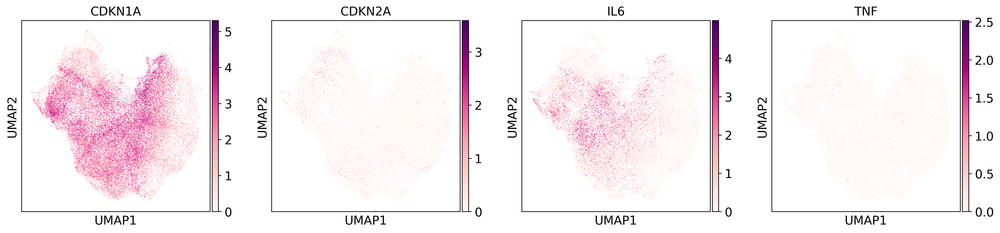

In [71]:
sc.pl.umap(adata, color = ['CDKN1A', 'CDKN2A', 'IL6', 'TNF'])

In [70]:
adata.obs['taa_l7-leiden_r0.2'].cat.categories

Index(['Fb-adipo', 'Fb-interlo,0', 'Fb-interlo,1', 'Fb-interlo,2',
       'Fb-interlo,3', 'Fb-interlo_PI16,0', 'Fb-interlo_PI16,1', 'Fb-interm',
       'Fb-med', 'Fb-perilo', 'Fb-perilo_COLEC11'],
      dtype='object')

In [72]:
adata.obs['taa_l5'] = adata.obs['taa_l7-leiden_r0.2'].apply(lambda x: 'Fb-interlo_PI16' if x == 'Fb-interlo_PI16,0' else
                                                           'Fb-interlo_PI16a' if x == 'Fb-interlo_PI16,1' else
                                                           'Fb-interlo' if x in ['Fb-interlo,0', 'Fb-interlo,1', 'Fb-interlo,2',
       'Fb-interlo,3'] else x)

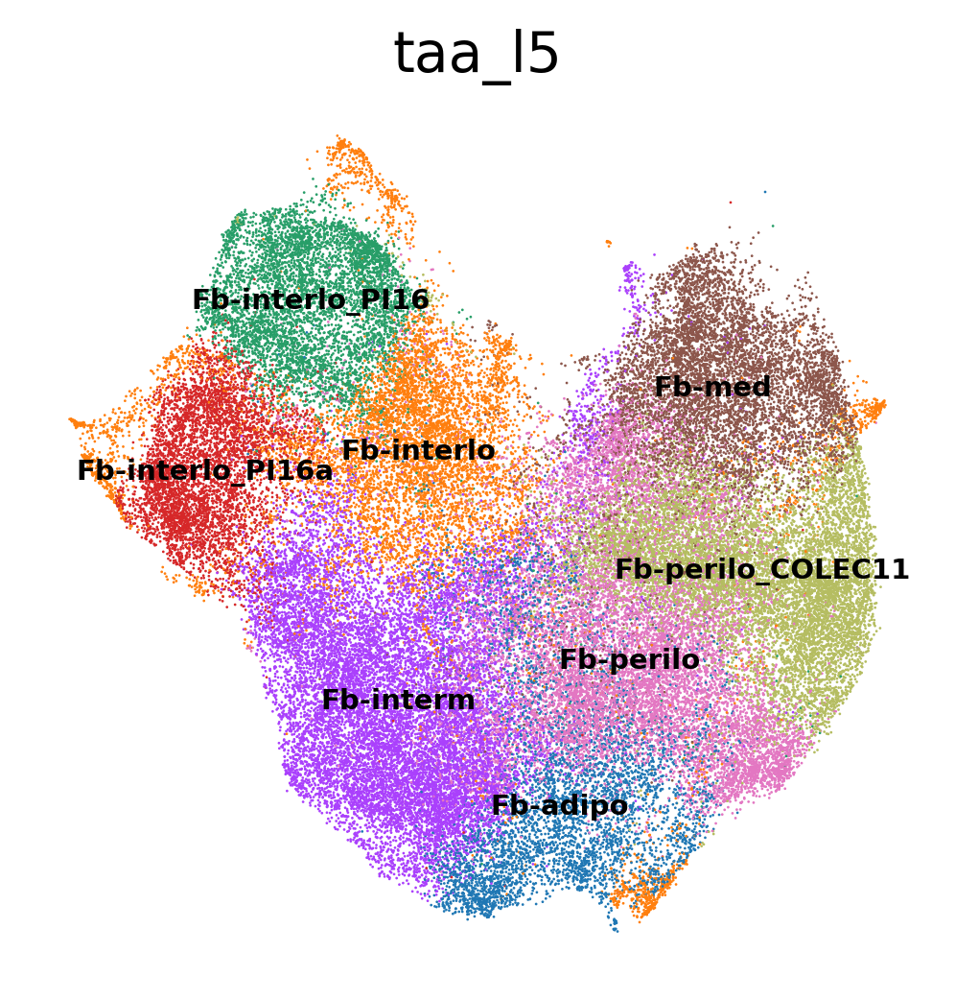

In [74]:
sc.pl.umap(adata, color = ['taa_l5'], legend_loc = 'on data', legend_fontsize = 7, frameon = False)

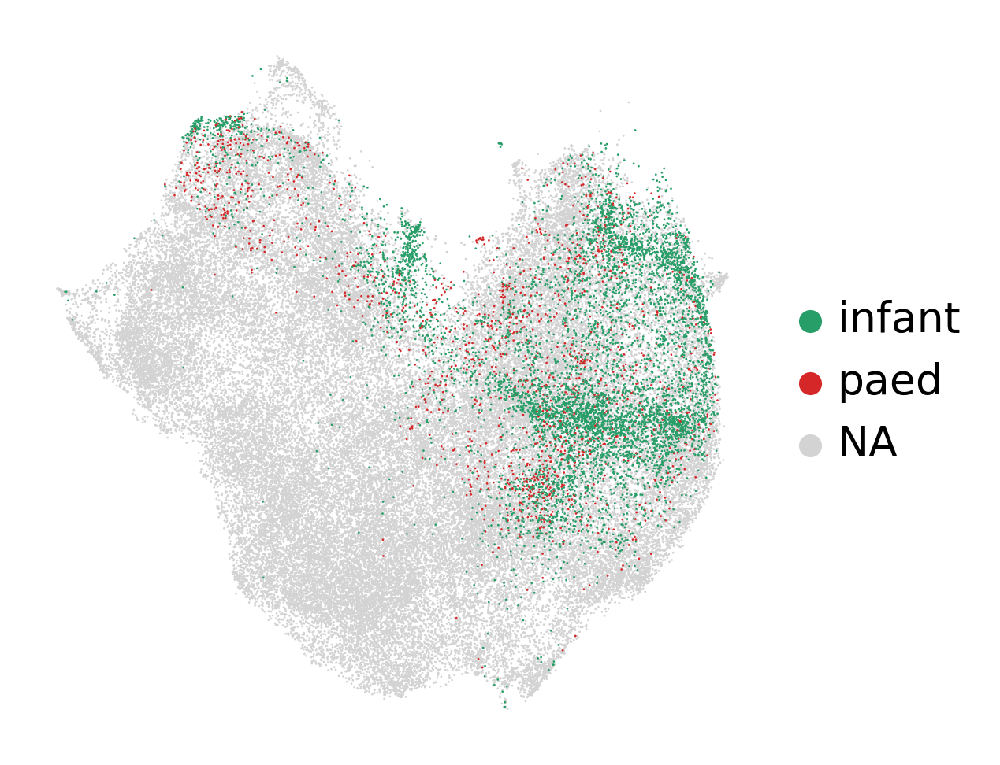

In [270]:
sc.pl.umap(adata, color = ['age_group'], groups = ['infant', 'paed'], title = '', frameon = False)

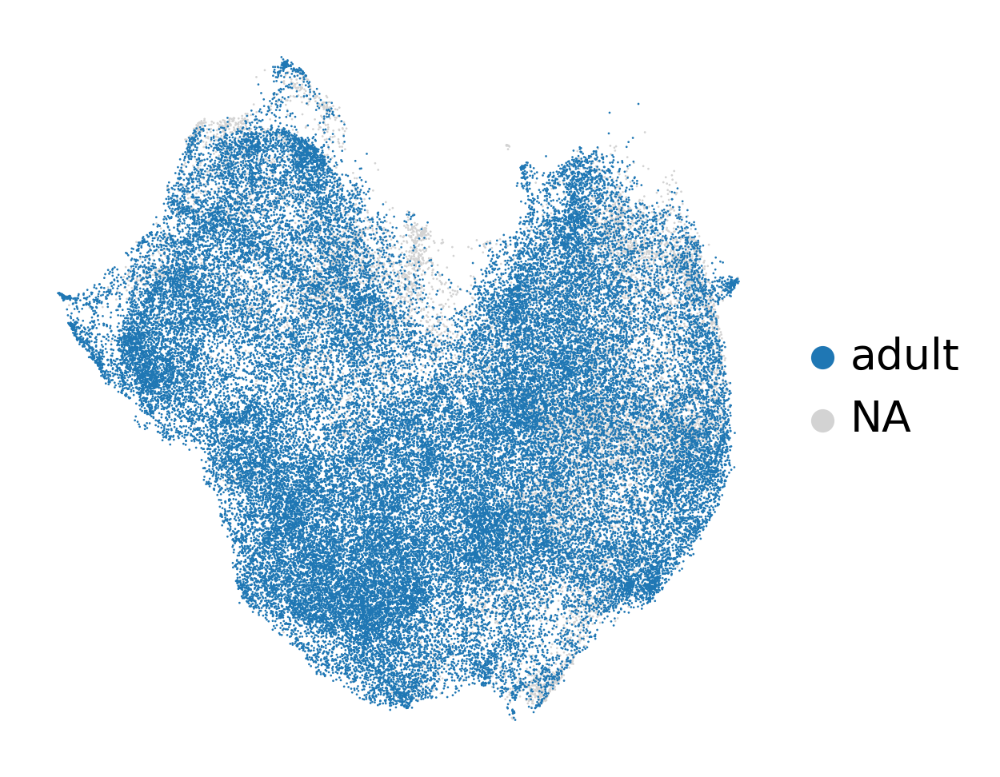

In [271]:
sc.pl.umap(adata, color = ['age_group'], groups = ['adult'], title = '', frameon = False)

In [75]:
fbs_mrkrs_full = {'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
             'Interlobular (PI16 progenitor)': ['MFAP5', 'CD55', 'FBN1','SEMA3C', 'PI16','PCOLCE2'],
            'PI16 aged': ['ALDH1A3', 'HAS1'],
             'Intermediate': ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
             'Parenchymal': ['C7', 'APOD', 'FBLN5', 'MFAP4', 'LUM', 'FMO2'],
             'Perilobular (progenitor)': ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'],
             'Medullary (antigen-presenting)': ['HLA-DRA',  'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
             'FDC':['CXCL13', 'FDCSP'],
             'Adipose': ['CXCL12','PPARG', 'APOE', 'PPP1R1A', 'PLIN1', 'LIPE','CIDEA', 'MRAP', 'AQP7']
             }
fbs_mrkrs_full_lst=[]
[fbs_mrkrs_full_lst.extend(fbs_mrkrs_full[key]) for key in fbs_mrkrs_full.keys()]

[None, None, None, None, None, None, None, None, None]

In [252]:
fbs_mrkrs_full_filt = {'General': ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1'],
             'Interlobular\n(PI16 progenitor)': ['MFAP5', 'CD55', 'FBN1','SEMA3C', 'PI16','PCOLCE2'],
            'PI16 aged': ['ALDH1A3', 'HAS1'],
             'Intermediate': ['PTX3', 'FOSL1', 'TNFRSF12A', 'HMOX1', 'IL1RL1', 'HMGA1','MT1X'],
            'Adipose': ['PPARG','PPP1R1A', 'PLIN1', 'LIPE'],
             'Perilobular': ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2', 'LAMC3'],
             'Medullary\n(antigen-presenting)': ['HLA-DRA',  'CD74', 'FRZB', 'CCL19', 'CCL21', 'IL33'],
             }
fbs_mrkrs_full_lst=[]
[fbs_mrkrs_full_lst.extend(fbs_mrkrs_full[key]) for key in fbs_mrkrs_full.keys()]

[None, None, None, None, None, None, None, None, None]

In [253]:
fb_subsets_fine = ['Fb-interlo_PI16', 'Fb-interlo_PI16a', 'Fb-interlo', 'Fb-interm', 'Fb-adipo', 'Fb-perilo',
       'Fb-perilo_COLEC11', 'Fb-med']

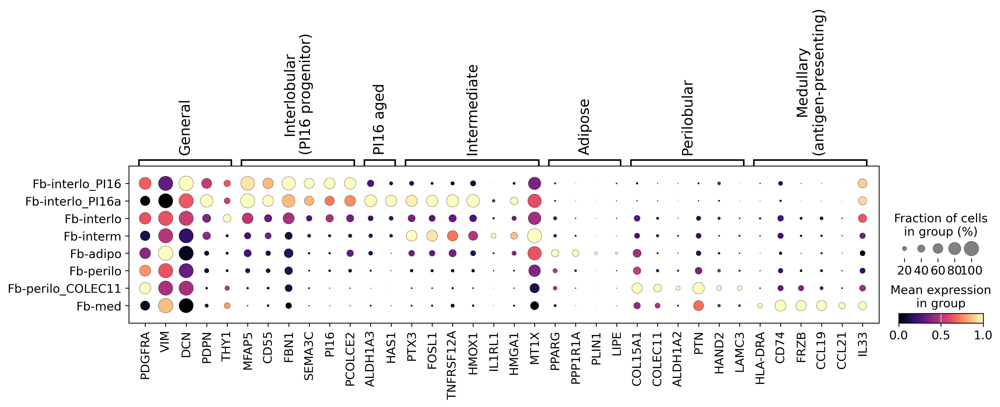

In [255]:
sc.pl.dotplot(adata,categories_order = fb_subsets_fine,var_names = fbs_mrkrs_full_filt, groupby = 'taa_l5', 
              cmap = 'magma', standard_scale='var')

In [82]:
fb_mrkrs = scvi_markers_enrich(vae = vae, cluster = 'taa_l5', adata = adata, enrich = True)

DE...: 100%|█████████████████████████████████████████████████████████████████████████████████████| 8/8 [02:22<00:00, 17.87s/it]
Number of significant genes:798


In [87]:
enrich_df = fb_mrkrs['enrich'][fb_mrkrs['enrich']['significant']==True].copy()

In [90]:
enrich_df.to_csv( f'{data_path}/thyAgeing_Fbs_v2_2layers_300epochs_batch-sample_mrkrs_enrich2.csv')